In [1]:
# 1- setup
import os, json, hashlib
from pathlib import Path
import numpy as np, pandas as pd
from PIL import Image, ImageDraw
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

root = Path.cwd()
while not (root / "data" / "imgs_cleaned").exists() and root != root.parent:
    root = root.parent
os.chdir(root)
print("working in:", Path.cwd())

CLEAN = Path("data/imgs_cleaned")
OUT = Path("logs/preprocess_a1"); (OUT / "sheets").mkdir(parents=True, exist_ok=True)
META = Path("data/meta"); META.mkdir(parents=True, exist_ok=True)
EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

# soft thresholds: a flag only means "look at this". Nothing is dropped here.
T = dict(low_res=160, aspect=2.0, dark=40, bright=225, low_contrast=25,
         blur=30, pad=0.12, gray=6, sym=0.96)

working in: c:\Projects\University\Sri-Lankan-Food-Recognition-and-Information-System


In [8]:
# 2- measure every image + flag
mp = Path("logs/dedup/manifest.csv")
if mp.exists():
    man = pd.read_csv(mp, dtype={"group": str})
    man["file"] = man.file.str.replace("\\", "/", regex=False)
    src, grp = dict(zip(man.file, man.source)), dict(zip(man.file, man.group))
else:
    src, grp = {}, {}

def lap_var(g):                                   # blur score: variance of the Laplacian
    c = g[1:-1, 1:-1]
    return float((4*c - g[:-2, 1:-1] - g[2:, 1:-1] - g[1:-1, :-2] - g[1:-1, 2:]).var())

def pad_frac(g, axis):                            # share of edge rows/cols that are flat (borders)
    u = (g.std(axis=1) if axis == 0 else g.std(axis=0)) < 4
    def run(a):
        n = 0
        for v in a:
            if not v: break
            n += 1
        return n
    return min(1.0, (run(u) + run(u[::-1])) / len(u))

def sym(g, axis):                                 # 1.0 = both halves are mirror images
    h = g.shape[axis] // 2
    if axis == 0: a, b = g[:h], g[-h:][::-1]
    else:         a, b = g[:, :h], g[:, -h:][:, ::-1]
    return 1 - float(np.abs(a - b).mean()) / 255

rows = []
for p in tqdm(sorted(q for q in CLEAN.rglob("*") if q.suffix.lower() in EXTS)):
    rel = p.relative_to(CLEAN).as_posix()
    rec = dict(file=rel, cls=p.parent.name, source=src.get(rel, "?"),
               group=grp.get(rel, "?"), bytes=p.stat().st_size)
    try:
        with Image.open(p) as im:
            im = im.convert("RGB"); rec["w"], rec["h"] = im.size
            t = im.copy(); t.thumbnail((256, 256))
        a = np.asarray(t, dtype=np.float32); g = np.asarray(t.convert("L"), dtype=np.float32)
        rec.update(bright=g.mean(), contrast=g.std(), blur=lap_var(g),
                   pad_v=pad_frac(g, 0), pad_h=pad_frac(g, 1),
                   sym_lr=sym(g, 1), sym_tb=sym(g, 0),
                   chroma=float((np.abs(a[..., 0] - a[..., 1]) + np.abs(a[..., 1] - a[..., 2])).mean()),
                   sha1=hashlib.sha1(p.read_bytes()).hexdigest(), ok=True)
    except Exception as e:
        rec.update(ok=False, err=str(e))
    rows.append(rec)
df = pd.DataFrame(rows)

df["short"] = df[["w", "h"]].min(axis=1)
df["long_short"] = df[["w", "h"]].max(axis=1) / df.short
df["pad"] = df[["pad_v", "pad_h"]].max(axis=1)
df["sym"] = df[["sym_lr", "sym_tb"]].max(axis=1)
F = {"low_res": df.short < T["low_res"], "extreme_aspect": df.long_short > T["aspect"],
     "dark": df.bright < T["dark"], "too_bright": df.bright > T["bright"],
     "low_contrast": df.contrast < T["low_contrast"], "blurry": df.blur < T["blur"],
     "padded": df.pad > T["pad"], "grayscale": df.chroma < T["gray"],
     "mirror_like": df.sym > T["sym"], "exact_dup": df.duplicated("sha1", keep=False)}
for k, v in F.items(): df[k] = v
df["flags"] = df[list(F)].apply(lambda r: ",".join(k for k in F if r[k]), axis=1)
df["n_flags"] = df[list(F)].sum(axis=1)
df.to_csv(OUT / "measurements.csv", index=False)

print("images:", len(df), "| unreadable:", int((~df.ok).sum()))
print(df.groupby("cls")[list(F)].sum())
print(df[["short", "long_short", "bright", "contrast", "blur", "sym", "chroma"]]
      .describe(percentiles=[.02, .05, .5, .95, .98]).round(2).T)

  0%|          | 0/1371 [00:00<?, ?it/s]

images: 1371 | unreadable: 0
                low_res  extreme_aspect  dark  too_bright  low_contrast  \
cls                                                                       
dosa                  0               0     0           0             0   
hoppers               0               0     0           2             0   
idli                  0               0     0           1             1   
kottu                 0               0     0           0             0   
milk_rice             0               0     1           0             0   
paratha               0               0     0           0             0   
pittu                 0               0     0           0             0   
rice                  0               0     1           7             3   
string_hoppers        0               0     0           0             0   

                blurry  padded  grayscale  mirror_like  exact_dup  
cls                                                                
dosa     

In [9]:
# 3- shortcut check: can metadata alone predict the class?
print(df.groupby("cls")[["short", "long_short", "bytes"]].median().round(1))
print(pd.crosstab(df.cls, df.source))

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import balanced_accuracy_score

d = df[df.ok]
X = d[["w", "h", "long_short", "bytes", "bright", "contrast", "blur", "chroma"]].values
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
pred = cross_val_predict(RandomForestClassifier(300, random_state=42, class_weight="balanced"),
                         X, d.cls.values, cv=cv, groups=d.group.values)
print("metadata-only balanced accuracy:", round(balanced_accuracy_score(d.cls, pred), 3),
      "| pure chance:", round(1/9, 3))

                short  long_short     bytes
cls                                        
dosa            640.0         1.0  103180.0
hoppers         640.0         1.0   86122.0
idli            640.0         1.0  105367.5
kottu           640.0         1.0  116642.0
milk_rice       640.0         1.0   86785.0
paratha         432.0         1.0   62524.0
pittu           704.0         1.0  169391.0
rice            640.0         1.0   86783.0
string_hoppers  640.0         1.0  103361.0
source          existing_dataset  new_dataset  new_dataset_a  new_dataset_b  \
cls                                                                           
dosa                          49          132              0              0   
hoppers                       81           75              0              0   
idli                          50           36              0              0   
kottu                         28            0              3             35   
milk_rice                     72          

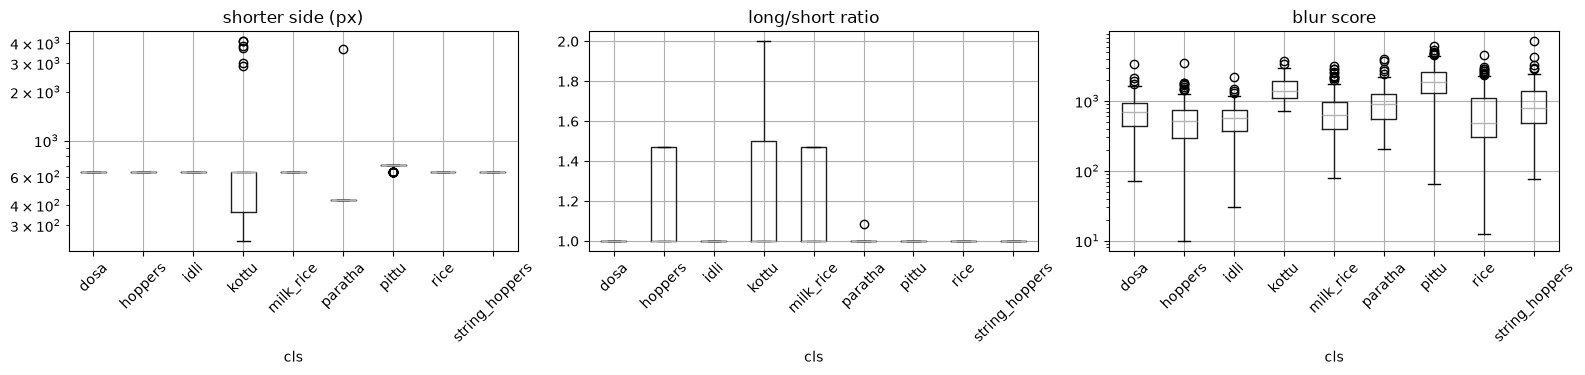

In [10]:
# 4- per-class distributions
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
d.boxplot("short", by="cls", ax=ax[0], rot=45); ax[0].set_yscale("log"); ax[0].set_title("shorter side (px)")
d.boxplot("long_short", by="cls", ax=ax[1], rot=45); ax[1].set_title("long/short ratio")
d.boxplot("blur", by="cls", ax=ax[2], rot=45); ax[2].set_yscale("log"); ax[2].set_title("blur score")
plt.suptitle(""); plt.tight_layout(); plt.savefig(OUT / "class_distributions.png", dpi=120); plt.show()

In [11]:
# 5- contact sheets (48 per page) for flagged images
def make_sheet(files, labels, path, cols=8, rows=6, th=160):
    sheet = Image.new("RGB", (cols * th, rows * (th + 22)), "white"); dr = ImageDraw.Draw(sheet)
    for i, (f, l) in enumerate(zip(files, labels)):
        im = Image.open(CLEAN / f).convert("RGB"); im.thumbnail((th, th))
        x, y = (i % cols) * th, (i // cols) * (th + 22)
        sheet.paste(im, (x, y))
        dr.text((x + 2, y + th + 1), f.split("/")[-1], fill="black")
        dr.text((x + 2, y + th + 11), l[:26], fill="red")
    sheet.save(path, quality=90)

for f in (OUT / "sheets").glob("flagged_*.jpg"): f.unlink()
fl = d[d.n_flags > 0].sort_values(["cls", "n_flags"], ascending=[True, False])
print(len(fl), "flagged of", len(d))
for i in range(0, len(fl), 48):
    ch = fl.iloc[i:i + 48]
    make_sheet(ch["file"].tolist(), ch["flags"].tolist(),
               OUT / "sheets" / f"flagged_{i // 48 + 1:02d}.jpg")
fl[["file", "cls", "source", "flags", "short", "long_short", "bright", "contrast",
    "blur", "pad", "sym", "chroma"]].to_csv(OUT / "flagged.csv", index=False)
print("sheets in", OUT / "sheets")

102 flagged of 1371
sheets in logs\preprocess_a1\sheets


In [7]:
# 6- class map + lookup check (the model→UI link)
FOLDER_TO_LOOKUP = {"dosa": "Dosa", "hoppers": "Hoppers", "idli": "Idli", "kottu": "Kottu",
                    "milk_rice": "Milk Rice", "paratha": "Parata", "pittu": "Pittu",
                    "rice": "Rice", "string_hoppers": "String Hoppers"}
lk = pd.read_csv("data/food_info/data/food_lookup.csv")      # adjust if you placed it elsewhere
folders = sorted(p.name for p in CLEAN.iterdir() if p.is_dir())
assert folders == sorted(FOLDER_TO_LOOKUP), folders
print("lookup rows:", len(lk),
      "| missing in lookup:", set(FOLDER_TO_LOOKUP.values()) - set(lk.class_name),
      "| extra in lookup:", set(lk.class_name) - set(FOLDER_TO_LOOKUP.values()))

cm = pd.DataFrame({"class_idx": range(len(folders)), "folder": folders})
cm["lookup_name"] = cm.folder.map(FOLDER_TO_LOOKUP)
cm = cm.merge(lk[["class_name", "display_name", "status"]], left_on="lookup_name",
              right_on="class_name", how="left").drop(columns="class_name")
cm["n_images"] = cm.folder.map(d.cls.value_counts())
cm.to_csv(META / "class_map.csv", index=False)
json.dump({i: f for i, f in enumerate(folders)}, open(META / "classes.json", "w"), indent=2)
print(cm)

lookup rows: 9 | missing in lookup: set() | extra in lookup: set()
   class_idx          folder     lookup_name                  display_name  \
0          0            dosa            Dosa            Plain Dosa (Dosai)   
1          1         hoppers         Hoppers          Plain Hoppers (Appa)   
2          2            idli            Idli                    Plain Idli   
3          3           kottu           Kottu            Chicken Kottu Roti   
4          4       milk_rice       Milk Rice          Milk Rice (Kiribath)   
5          5         paratha          Parata      Layered Parotta (Parata)   
6          6           pittu           Pittu  Rice Flour and Coconut Pittu   
7          7            rice            Rice              Plain White Rice   
8          8  string_hoppers  String Hoppers     String Hoppers (Indiappa)   

      status  n_images  
0  estimated       181  
1   reported       156  
2  estimated        86  
3  estimated        66  
4   reported       143  
5 

In [12]:
# 7- Roboflow "cutout" artifacts: solid black rectangles painted onto the photo
from scipy import ndimage

def find_black_boxes(path, thr=12, min_frac=0.02, max_frac=0.30, fill=0.90):
    with Image.open(path) as im:
        im = im.convert("RGB"); im.thumbnail((320, 320))
    a = np.asarray(im)
    H, W = a.shape[:2]
    lab, n = ndimage.label(a.max(axis=2) <= thr)
    boxes = []
    for i, sl in enumerate(ndimage.find_objects(lab), start=1):
        h, w = sl[0].stop - sl[0].start, sl[1].stop - sl[1].start
        if not (min_frac * min(H, W) <= min(h, w) and max(h, w) <= max_frac * max(H, W)):
            continue                                   # too small, or too big (bars / black backgrounds)
        if (lab[sl] == i).sum() / (h * w) >= fill:     # must be a filled rectangle
            boxes.append((sl[1].start, sl[0].start, w, h))
    return boxes

hits = []
for f in tqdm(d.file.tolist()):
    b = find_black_boxes(CLEAN / f)
    if b: hits.append(dict(file=f, cls=f.split("/")[0], n_boxes=len(b), boxes=str(b)))
bb = pd.DataFrame(hits, columns=["file", "cls", "n_boxes", "boxes"])
bb.to_csv(OUT / "black_boxes.csv", index=False)
print("images with black-box artifacts:", len(bb), "of", len(d))
print(bb.cls.value_counts().to_string() if len(bb) else "none")

for f in (OUT / "sheets").glob("blackbox_*.jpg"): f.unlink()
for i in range(0, len(bb), 48):
    ch = bb.iloc[i:i + 48]
    make_sheet(ch["file"].tolist(), [f"{n} box(es)" for n in ch["n_boxes"]],
               OUT / "sheets" / f"blackbox_{i // 48 + 1:02d}.jpg")

  0%|          | 0/1371 [00:00<?, ?it/s]

images with black-box artifacts: 31 of 1371
cls
rice         26
hoppers       2
milk_rice     2
kottu         1


In [13]:
# 8- letterbox / pillarbox bars -> crop boxes (nothing is modified on disk)
def flat_run(flat):                                    # flat lines at the start / end
    def run(v):
        n = 0
        for x in v:
            if not x: break
            n += 1
        return n
    return run(flat), run(flat[::-1])

def letterbox_box(path, band=0.04, edge=0.02, std_t=5, tone_t=25, margin=0.01):
    with Image.open(path) as im:
        im = im.convert("RGB"); W0, H0 = im.size
        t = im.copy(); t.thumbnail((256, 256))
    g = np.asarray(t, dtype=np.float32).mean(axis=2); H, W = g.shape
    colflat, rowflat = g.std(axis=0) < std_t, g.std(axis=1) < std_t
    l, r = flat_run(colflat); tp, bt = flat_run(rowflat)
    if l >= band * W and r >= band * W and tp <= edge * H and bt <= edge * H:       # side bars
        if abs(g[:, :max(l, 1)].mean() - g[:, W - max(r, 1):].mean()) > tone_t: return None
        x0, x1, y0, y1, kind = l, W - r, 0, H, "side_bars"
    elif tp >= band * H and bt >= band * H and l <= edge * W and r <= edge * W:      # top/bottom bars
        if abs(g[:max(tp, 1)].mean() - g[H - max(bt, 1):].mean()) > tone_t: return None
        x0, x1, y0, y1, kind = 0, W, tp, H - bt, "top_bottom_bars"
    else:
        return None                                    # object on plain background, or no bars: leave alone
    mx, my = int(margin * (x1 - x0)), int(margin * (y1 - y0))
    sx, sy = W0 / W, H0 / H
    box = (int((x0 + mx) * sx), int((y0 + my) * sy), int((x1 - mx) * sx), int((y1 - my) * sy))
    if box[2] - box[0] < 0.3 * W0 or box[3] - box[1] < 0.3 * H0: return None         # sanity
    return kind, box

rows_ = []
for f in tqdm(d.file.tolist()):
    r = letterbox_box(CLEAN / f)
    if r:
        kind, (x0, y0, x1, y1) = r
        w, h = d.loc[d.file == f, ["w", "h"]].iloc[0]
        rows_.append(dict(file=f, cls=f.split("/")[0], kind=kind, x0=x0, y0=y0, x1=x1, y1=y1,
                          kept_area=round((x1 - x0) * (y1 - y0) / (w * h), 3)))
lb = pd.DataFrame(rows_, columns=["file", "cls", "kind", "x0", "y0", "x1", "y1", "kept_area"])
lb.to_csv(OUT / "letterbox.csv", index=False)
print("images with bars:", len(lb), "of", len(d))
print(pd.crosstab(lb.cls, lb.kind) if len(lb) else "none")
print("kept area: ", lb.kept_area.describe().round(2).to_dict() if len(lb) else "")

def pair_sheet(items, path, cols=4, th=160):           # original | cropped, side by side
    n = len(items); nr = -(-n // cols)
    sheet = Image.new("RGB", (cols * 2 * th, nr * (th + 14)), "white"); dr = ImageDraw.Draw(sheet)
    for i, (f, box) in enumerate(items):
        im = Image.open(CLEAN / f).convert("RGB")
        a = im.copy(); a.thumbnail((th - 4, th - 4))
        b = im.crop(box); b.thumbnail((th - 4, th - 4))
        x, y = (i % cols) * 2 * th, (i // cols) * (th + 14)
        sheet.paste(a, (x, y)); sheet.paste(b, (x + th, y))
        dr.text((x + 2, y + th), f.split("/")[-1], fill="black")
    sheet.save(path, quality=90)

for f in (OUT / "sheets").glob("letterbox_*.jpg"): f.unlink()
items = [(r.file, (r.x0, r.y0, r.x1, r.y1)) for r in lb.itertuples()]
for i in range(0, len(items), 24):
    pair_sheet(items[i:i + 24], OUT / "sheets" / f"letterbox_{i // 24 + 1:02d}.jpg")
print("sheets in", OUT / "sheets")

  0%|          | 0/1371 [00:00<?, ?it/s]

images with bars: 75 of 1371
kind            side_bars  top_bottom_bars
cls                                       
dosa                    0                2
hoppers                21               11
idli                    1                1
milk_rice              22                9
paratha                 1                3
pittu                   0                3
string_hoppers          1                0
kept area:  {'count': 75.0, 'mean': 0.71, 'std': 0.15, 'min': 0.38, '25%': 0.62, '50%': 0.74, '75%': 0.83, 'max': 0.89}
sheets in logs\preprocess_a1\sheets
